# File 4: Risk & Value Screen (Auckland)

## Purpose
Bring Files 1–3 together into one transparent screen of SA2s for a residential investor: what each area earns (value),
how its rent and population have grown (growth), and what could go wrong (risk). Every score is a simple percentile rank
that can be traced back to one column, and the weights are tested to see how much the ranking depends on them.

**This is a research screen, not investment advice.** It narrows ~600 SA2s to a shortlist worth looking at properly.
It knows nothing about a specific property, its condition, financing, tax, or flood and land hazards.

## Inputs
| File | What |
|---|---|
| `data/clean/master_flagged.csv` | CV, yield, crime, flags (File 1) |
| `data/clean/rent_metrics_by_sa2.csv` | Rent growth, 3-bed house rent (File 2) |
| `data/clean/area_profiles_by_sa2.csv` | Area type (File 3) |
| `data/clean/rent_timeseries_by_sa2.csv` | Quarterly rent, for rent volatility |
| `data/clean/rent_market_by_sa2.csv` | Rent change over the last 2 years (File 5), shown next to the score, not scored |

## Who is screened
Analysis-ready SA2s, **excluding** crime hotspots (crime rate not comparable, File 1) and SA2s where fewer than half the
dwellings are separate houses. Yield here is all-dwelling rent over all-property CV, and that ratio is only like-for-like
where both mostly describe houses (File 1 showed apartment SA2s get inflated yields from small units' low CVs).

## What two inputs actually measure
- **Gross yield is a proxy:** annualised all-dwelling bond rent divided by the SA2's median **2024 council capital value**
  (all property types). It is not a sale-price yield.
- **Crime is recorded victimisations per 1,000 residents** (NZ Police, latest 12 months). Visitors are not counted in the
  denominator, so shopping and town centres score high, and Police data leaves out crimes inside homes other than burglary.

## Who is ranked
- Only SA2s with **all seven inputs** are ranked. The 34 missing an input are listed with what they lack; nothing is filled
  in or averaged around (Step 3, compared with the previous rule in Step 7b).
- **New developments are listed, not ranked** (15 more). Where the population more than doubled from 2018 to 2023 **and**
  the rent comes from a 2018 source SA2 shared with other SA2s (`is_new_development`), the rent history (10-year growth,
  volatility) describes the source area's older housing. Step 7c shows what ranking them would change.
- An SA2 that doubled but has its own rent series stays ranked with `flag_rapid_growth` (one: Long Bay, rank 259).
- That leaves **481 ranked SA2s**.

## Rental market depth for shared-rent SA2s
SA2s sharing an MBIE source SA2 share its bond count. The bonds are split in proportion to each SA2's rented households
(households × (1 − owner-occupied share)), not evenly. Step 7c compares the two.

## Steps
1. Load, join and define the screened universe
2. Rent volatility from the quarterly series
3. Build the measures and percentile scores
4. Combine into value, growth and risk scores
5. Value against growth, coloured by risk
6. Top of the screen and what drives each score
7. How much do the weights matter?
8. Map of the balanced score
9. Save outputs

In [1]:
# STEP 0: SETUP
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullFormatter

CLEAN = Path('data/clean')
VIZ = Path('visualizations'); VIZ.mkdir(exist_ok=True)

# Palette: categorical slots 1-2, single-hue sequential, orange-grey-blue diverging
BLUE, ORANGE, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#b9b8b3', '#0b0b0b', '#52514e'
SEQ = 'Blues'
DIV = LinearSegmentedColormap.from_list('div', [ORANGE, '#e6e5e1', BLUE])
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GREY, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': '#ecebe8', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10,
})
dollars = FuncFormatter(lambda v, _: f'${v/1e6:.1f}m' if v >= 1e6 else f'${v/1e3:.0f}k')
CV_TICKS = [1e5, 3e5, 5e5, 1e6, 2e6, 5e6, 1e7, 3e7]

def cv_axis(ax, lo, hi):
    ax.set_xscale('log'); ax.set_xticks([t for t in CV_TICKS if lo <= t <= hi])
    ax.xaxis.set_major_formatter(dollars); ax.xaxis.set_minor_formatter(NullFormatter())
pd.set_option('display.width', 160, 'display.max_columns', 40)

### Step 1: Load, join and define the universe

In [2]:
# STEP 1: LOAD AND JOIN
m = pd.read_csv(CLEAN / 'master_flagged.csv')
rent = pd.read_csv(CLEAN / 'rent_metrics_by_sa2.csv')
area = pd.read_csv(CLEAN / 'area_profiles_by_sa2.csv')
market = pd.read_csv(CLEAN / 'rent_market_by_sa2.csv')   # File 5: annualised rent change over the last 2 years
m = (m.merge(rent[['sa2_code', 'rent_cagr_10y_pct', 'rent_3bed_house', 'lodged_3bed_house_4q', 'flag_verify_3bed_house',
                    'rent_to_income_pct']], on='sa2_code', how='left')
      .merge(area[['sa2_code', 'area_type']], on='sa2_code', how='left')
      .merge(market[['sa2_code', 'cooling_pa']].rename(columns={'cooling_pa': 'rent_change_2y_pa'}), on='sa2_code', how='left'))
rent_ts = pd.read_csv(CLEAN / 'rent_timeseries_by_sa2.csv', parse_dates=['quarter'])
geo = gpd.read_file('data/boundaries/auckland_sa2_2023.geojson')
geo['sa2_code'] = geo['SA22023_V1_00'].astype(int)
assert len(m) == 633 and m.sa2_code.is_unique
# Shared rent: SA2s with the same MBIE source SA2 (rent_source_sa2) share its rent AND its whole bond count. Split the bonds
# in proportion to each SA2's rented households (households x (1 - owner-occupied share)), so a large SA2 isn't given the
# same rental market as a small one. Rented households include social housing, which private bonds don't cover.
m['rented_households'] = m.households_2023 * (1 - m.pct_owner_occupied / 100)
m['rent_area_size'] = m.groupby('rent_source_sa2').sa2_code.transform('size')
m['bond_share'] = m.rented_households / m.groupby('rent_source_sa2').rented_households.transform('sum')
m['bonds_per_sa2'] = m.active_bonds * m.bond_share
m['bonds_per_sa2_even'] = m.active_bonds / m.rent_area_size   # previous rule (even split), kept for the Step 7c comparison
# New development: population more than doubled 2018-23 AND rent borrowed from a 2018 source SA2 shared with other SA2s.
# Their rent history (10-year growth, volatility) describes the source area's older housing, so they are listed, not ranked
# (Step 3). An SA2 that doubled but has its own rent series (e.g. Long Bay) stays ranked with a rapid-growth badge.
fast = m.pop_change_2018_2023_pct > 100
m['is_new_development'] = fast & m.flag_borrowed_rent
m['flag_rapid_growth'] = fast & ~m.flag_borrowed_rent

steps ={'All SA2s': pd.Series(True, index=m.index)}
steps['analysis-ready'] = steps['All SA2s'] & m.analysis_ready
steps['not a crime hotspot'] = steps['analysis-ready'] & ~m.flag_crime_hotspot
steps['50%+ separate houses'] = steps['not a crime hotspot'] & (m.pct_separate_house >= 50)
steps['has rent and CV'] = steps['50%+ separate houses'] & m.median_rent_weekly.notna() & m.median_cv_2024.notna()
for k, v in steps.items():
    print(f'{k:>22}: {v.sum():>3} SA2s, {m.loc[v, "population_2023"].sum():>9,.0f} residents')
u = m[steps['has rent and CV']].copy()

              All SA2s: 633 SA2s, 1,656,417 residents
        analysis-ready: 599 SA2s, 1,644,108 residents
   not a crime hotspot: 586 SA2s, 1,625,490 residents
  50%+ separate houses: 540 SA2s, 1,507,503 residents
       has rent and CV: 530 SA2s, 1,495,344 residents


### Step 2: Rent volatility

In [3]:
# STEP 2: RENT VOLATILITY = standard deviation of the year-on-year % change in quarterly median rent, last 10 years.
# A steady market has small swings; a thin or changing one swings a lot. Needs 20+ year-on-year points.
p = rent_ts.pivot(index='quarter', columns='sa2_code', values='median_rent')
p = p.reindex(pd.date_range(p.index.min(), p.index.max(), freq='QS'))   # blank quarters stay blank, so pct_change(4) is truly a year apart
yoy = 100 * p.pct_change(4, fill_method=None)
yoy = yoy[yoy.index > yoy.index.max() - pd.DateOffset(years=10)]
vol = yoy.std().where(yoy.notna().sum() >= 20).rename('rent_volatility')
u = u.join(vol, on='sa2_code')
print(f'Volatility available for {u.rent_volatility.notna().sum()} of {len(u)} screened SA2s')
print(u.rent_volatility.describe(percentiles=[.1, .5, .9]).round(1).to_string())

Volatility available for 500 of 530 screened SA2s
count    500.0
mean      12.3
std       12.6
min        3.5
10%        5.9
50%        9.7
90%       19.6
max      223.5


**Reading this:** most SA2s swing by about ±10% a year. The extremes are small rental markets where a handful of
new bonds move the median, which is itself a risk for a landlord: rent is harder to predict there.

### Step 3: Measures and percentile scores

In [4]:
# STEP 3: MEASURES. Each becomes a percentile rank from 0 to 100 within the screened universe, flipped where lower is better,
# so 100 always means 'best for an investor on this measure'. Ranks ignore units and outliers (e.g. +7,000% population growth).
measures = pd.DataFrame([
    # column,                    group,    higher is better?, label
    ('gross_yield_pct',          'value',  True,  'Gross yield (2024 CV proxy)'),
    ('rent_cagr_10y_pct',        'growth', True,  'Rent growth, 10y a year'),
    ('pop_change_2018_2023_pct', 'growth', True,  'Population growth 2018-23'),
    ('crime_per_1000_residents', 'risk',   False, 'Recorded victimisations /1,000 residents'),
    ('rent_volatility',          'risk',   False, 'Rent volatility'),
    ('cv_change_2021_2024_pct',  'risk',   True,  'CV change 2021-24 (smaller fall)'),
    ('bonds_per_sa2',            'risk',   True,  'Rental market depth (bonds)'),
], columns=['col', 'group', 'higher_better', 'label'])

INPUTS = list(measures.col)

# MISSING-DATA RULE: rank only SA2s with all seven inputs. A missing input is never filled in, and never skipped inside a group
# average (skipping gives that SA2's other measures more weight). SA2s missing an input are listed with what is missing, not ranked.
u['missing_inputs'] = u[INPUTS].isna().apply(lambda r: ', '.join(r.index[r]), axis=1)
incomplete = u[u.missing_inputs != ''].copy()
print(f'Screened: {len(u)} | all 7 inputs: {len(u) - len(incomplete)} | missing at least one (listed, not ranked): {len(incomplete)}')
print(incomplete.missing_inputs.value_counts().to_string())
all_screened = u.copy()   # kept to compare with the previous skip-missing rule (Step 7b)
newdev = u[(u.missing_inputs == '') & u.is_new_development].copy()
print(f'Complete but new development (population more than doubled 2018-23; listed, not ranked): {len(newdev)}, '
      f'{newdev.flag_borrowed_rent.sum()} of them sharing a 2018 source SA2\'s rent')
u = u[(u.missing_inputs == '') & ~u.is_new_development].copy()
assert u.bonds_per_sa2.notna().all()
print(f'Ranked: {len(u)}')

def percentile_scores(d):
    # percentile rank within the SA2s being ranked; 100 = best for an investor on that measure
    for r in measures.itertuples():
        d[f's_{r.col}'] = d[r.col].rank(pct=True, ascending=r.higher_better) * 100
    return d
u = percentile_scores(u)

Screened: 530 | all 7 inputs: 496 | missing at least one (listed, not ranked): 34
missing_inputs
rent_volatility                       29
rent_cagr_10y_pct                      3
rent_cagr_10y_pct, rent_volatility     1
pop_change_2018_2023_pct               1
Complete but new development (population more than doubled 2018-23; listed, not ranked): 15, 15 of them sharing a 2018 source SA2's rent
Ranked: 481


**Why these and not others.** Risk here means risk to the investment: crime, rent that is hard to predict, prices that fell
furthest from the 2021 peak, and a small rental market (fewer tenants, longer vacancies). Demographics such as ethnicity,
religion or crowding are deliberately **not** used as risk: they describe people, not investment outcomes, and using them
would bake neighbourhood stereotypes into a ranking.

### Step 4: Value, growth and risk scores

In [5]:
# STEP 4: GROUP SCORES = mean of the group's percentile scores; then a weighted total.
# risk_score reads as 'safety': 100 = lowest risk on these measures.
PROFILES = {'Balanced': (1/3, 1/3, 1/3), 'Income-focused': (0.5, 0.25, 0.25), 'Cautious': (0.25, 0.25, 0.5)}

def group_scores(d):
    for g in ['value', 'growth', 'risk']:
        d[f'{g}_score'] = d[[f's_{c}' for c in measures.loc[measures.group == g, 'col']]].mean(axis=1)
    for name, (wv, wg, wr) in PROFILES.items():
        d[f'score_{name}'] = wv * d.value_score + wg * d.growth_score + wr * d.risk_score
        d[f'rank_{name}'] = d[f'score_{name}'].rank(ascending=False, method='min').astype(int)
    return d
u = group_scores(u)
assert u[[f'{g}_score' for g in ['value', 'growth', 'risk']]].notna().all().all()   # complete inputs: no skipped measures

print('How the three group scores relate (Spearman):')
u[['value_score', 'growth_score', 'risk_score']].corr(method='spearman').round(2)

How the three group scores relate (Spearman):


,value_score,growth_score,risk_score
value_score,1.00,0.28,0.18
growth_score,0.28,1.00,0.11
risk_score,0.18,0.11,1.00


**Reading this:** value, growth and risk barely move together (correlations 0.10–0.28), so each score adds information
the others don't. There is no strong trade-off either: high-yield SA2s are not systematically riskier on these measures.

### Step 5: Value against growth, coloured by risk

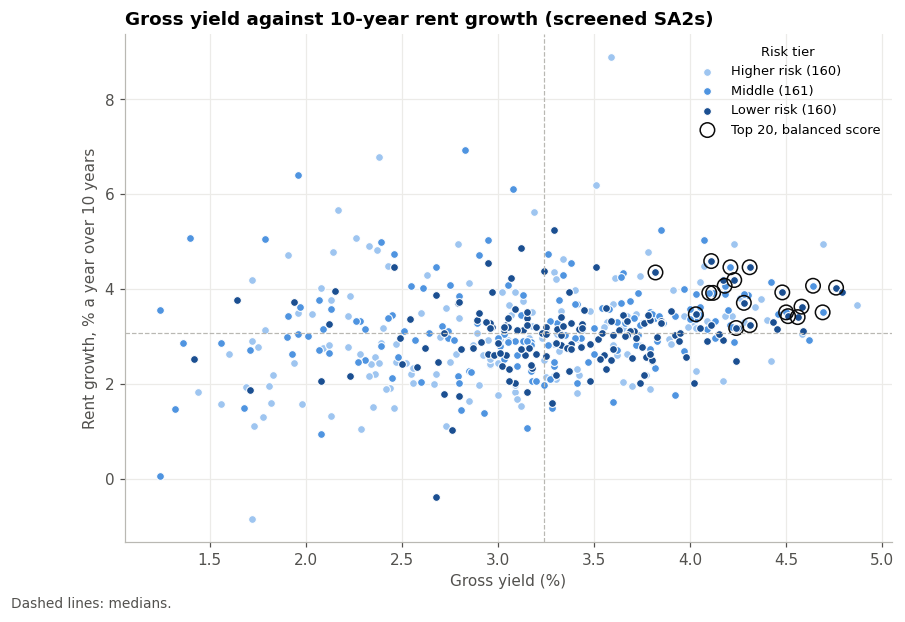

In [6]:
# STEP 5: YIELD vs RENT GROWTH, risk in three equal-sized tiers (ordered, so one hue light -> dark)
u['risk_tier'] = pd.qcut(u.risk_score, 3, labels=['Higher risk', 'Middle', 'Lower risk'])
tiers = {'Higher risk': '#9ec5f0', 'Middle': '#4f94e0', 'Lower risk': '#1b4f91'}
fig, ax = plt.subplots(figsize=(9, 6))
for t, colour in tiers.items():
    s = u[u.risk_tier == t]
    ax.scatter(s.gross_yield_pct, s.rent_cagr_10y_pct, s=26, color=colour, edgecolor='white', linewidth=0.7, label=f'{t} ({len(s)})')
ax.axvline(u.gross_yield_pct.median(), color=GREY, lw=0.8, ls='--'); ax.axhline(u.rent_cagr_10y_pct.median(), color=GREY, lw=0.8, ls='--')
t20 = u.nsmallest(20, 'rank_Balanced')   # ringed, not named: borrowed-rent pairs sit on the same point (names are in Step 6)
ax.scatter(t20.gross_yield_pct, t20.rent_cagr_10y_pct, s=90, facecolor='none', edgecolor=INK, linewidth=1, label='Top 20, balanced score')
ax.set(title='Gross yield against 10-year rent growth (screened SA2s)', xlabel='Gross yield (%)', ylabel='Rent growth, % a year over 10 years')
ax.legend(frameon=False, loc='upper right', title='Risk tier', title_fontsize=8.5, fontsize=8.5)
fig.text(0.01, 0.01, 'Dashed lines: medians.', color=MUTED, fontsize=9)
fig.savefig(VIZ / '04_yield_vs_growth.png'); plt.show()

### Step 6: Top of the screen

In [7]:
# STEP 6: TOP 20 (balanced weights) and the scores behind each
top = u.nsmallest(20, 'rank_Balanced')
print(f'3-bed house rent marked verify (File 2: under 30 new lodgements or unstable): {int(top.flag_verify_3bed_house.sum())} of the top 20')
print(f'Top 20 SA2s cover {top.rent_source_sa2.nunique()} distinct MBIE rent areas '
      f'({top.flag_borrowed_rent.sum()} share their rent figure with another SA2)')
# Rent change over the last 2 years (File 5, not scored) shown next to the 10-year growth that IS scored
rest = u[~u.sa2_code.isin(top.sa2_code)]
print(f'Rent change, last 2 years (% a year): top 20 median {top.rent_change_2y_pa.median():+.1f} ({(top.rent_change_2y_pa < 0).sum()} of 20 falling) | '
      f'other ranked SA2s {rest.rent_change_2y_pa.median():+.1f} ({(rest.rent_change_2y_pa < 0).mean():.0%} falling) | '
      f'top 20 among the 100 fastest-falling: {top.sa2_code.isin(u.nsmallest(100, "rent_change_2y_pa").sa2_code).sum()}')
show =['sa2_name', 'area_type', 'median_cv_2024', 'median_rent_weekly', 'rent_3bed_house', 'lodged_3bed_house_4q',
        'flag_verify_3bed_house', 'gross_yield_pct',
        'rent_cagr_10y_pct', 'rent_change_2y_pa', 'crime_per_1000_residents', 'value_score', 'growth_score', 'risk_score', 'score_Balanced', 'flag_borrowed_rent']
top[show].round(1).set_index('sa2_name')

3-bed house rent marked verify (File 2: under 30 new lodgements or unstable): 6 of the top 20
Top 20 SA2s cover 16 distinct MBIE rent areas (11 share their rent figure with another SA2)
Rent change, last 2 years (% a year): top 20 median -1.4 (15 of 20 falling) | other ranked SA2s -0.7 (59% falling) | top 20 among the 100 fastest-falling: 1


,area_type,median_cv_2024,median_rent_weekly,rent_3bed_house,lodged_3bed_house_4q,flag_verify_3bed_house,gross_yield_pct,rent_cagr_10y_pct,rent_change_2y_pa,crime_per_1000_residents,value_score,growth_score,risk_score,score_Balanced,flag_borrowed_rent
sa2_name,,,,,,,,,,,,,,,
Papatoetoe West,Crowded family suburbs,810000.0,671.2,685.0,42.0,False,4.3,4.5,3.4,31.0,95.3,89.8,68.3,84.5,True
Pukekohe North West,Crowded family suburbs,690000.0,598.8,611.2,54.0,False,4.5,3.4,-2.4,42.8,97.7,74.7,71.2,81.2,True
Gulf Harbour South,Older & coastal,977500.0,717.5,687.0,27.0,True,3.8,4.4,1.0,16.2,80.5,91.4,69.3,80.4,False
Pukekohe West,Crowded family suburbs,760000.0,626.2,607.5,87.0,False,4.3,3.7,-1.4,37.9,94.6,67.6,75.7,79.3,True
Homai Central,Crowded family suburbs,730000.0,658.2,667.5,51.0,False,4.7,3.5,-1.9,64.1,99.3,82.5,55.2,79.0,True
Rowandale East,Crowded family suburbs,770000.0,675.0,682.5,39.0,False,4.6,3.4,0.6,28.4,97.9,73.1,64.2,78.4,False
Rowandale West,Crowded family suburbs,740000.0,651.2,662.5,24.0,True,4.6,3.6,-2.2,31.6,98.2,71.8,64.4,78.2,False
Weymouth Central,Crowded family suburbs,780000.0,672.5,668.8,36.0,False,4.5,3.9,-1.5,15.9,97.3,65.9,71.2,78.1,True
Papatoetoe North West,Crowded family suburbs,830000.0,671.2,685.0,42.0,False,4.2,4.5,3.4,45.3,92.2,84.8,55.2,77.4,True


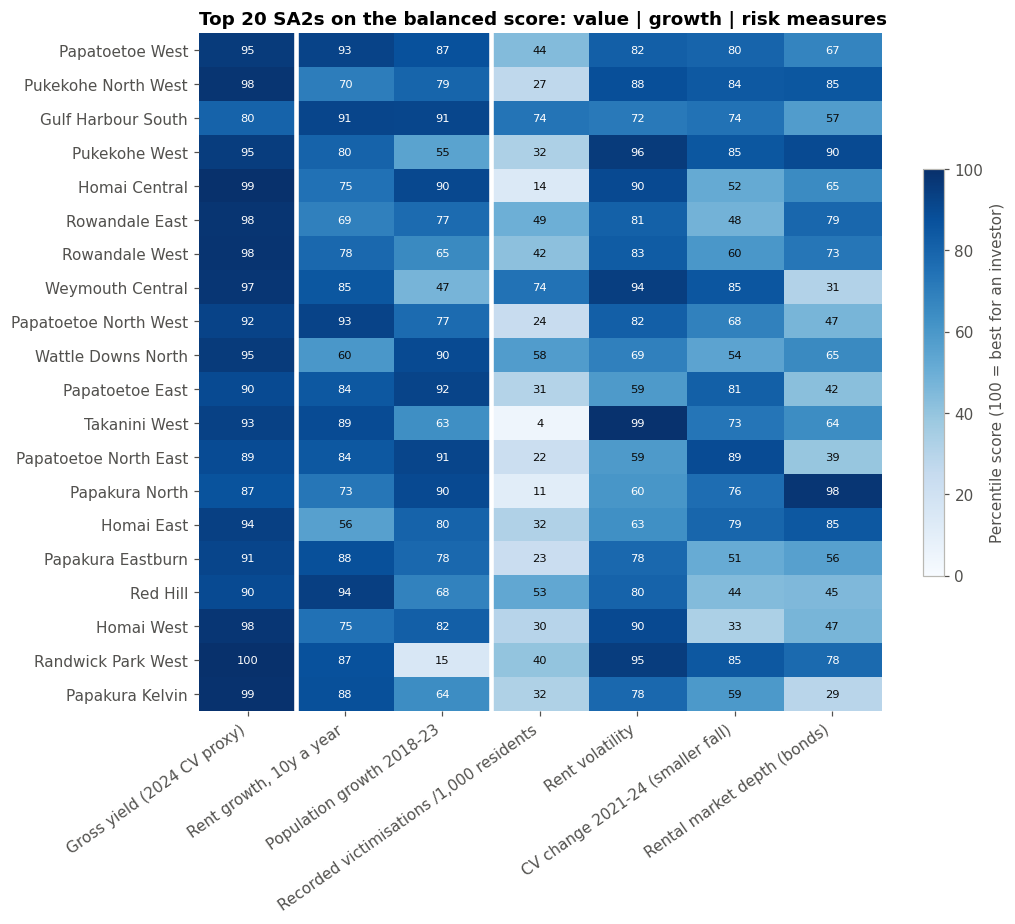

In [8]:
# Heatmap of the 7 measure scores for the top 20, so you can see WHY each ranks where it does
cols = [f's_{c}' for c in measures.col]
h = top.set_index('sa2_name')[cols].rename(columns=dict(zip(cols, measures.label)))
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(h, cmap=SEQ, vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(h.shape[1]), h.columns, rotation=35, ha='right'); ax.set_yticks(range(len(h)), h.index)
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        v = h.iat[i, j]
        ax.text(j, i, '–' if np.isnan(v) else f'{v:.0f}', ha='center', va='center', fontsize=7.5, color='white' if v > 60 else INK)
for x in [0.5, 2.5]:
    ax.axvline(x, color='white', lw=3)   # separates value | growth | risk
ax.grid(False); ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.6, label='Percentile score (100 = best for an investor)')
ax.set_title('Top 20 SA2s on the balanced score: value | growth | risk measures')
fig.savefig(VIZ / '04_top20_scores.png'); plt.show()

**Reading this:** the top of the screen is almost all South Auckland (Papatoetoe, Takanini, Pukekohe, Papakura, Manurewa)
with CVs mostly \$690k–865k. That follows from Files 1 and 2: yield is roughly the inverse of price, and cheaper areas had the
fastest rent growth. The heatmap shows the weak spot: 16 of the top 20 have above-median crime (lowest scores Takanini West,
Papakura North).

**3-bed house rent:** 6 of the top 20 have a 3-bed house rent marked `verify` in File 2 (Gulf Harbour South, Rowandale West,
Wattle Downs North, Takanini West, Homai East, Red Hill): each rests on 21–27 new lodgements over a year, under the 30 minimum.
`lodged_3bed_house_4q` and `flag_verify_3bed_house` sit next to the rent in the table and the output file.

**Recent rent (not scored):** the score rewards 10-year rent growth, but over the last two years 15 of the top 20 have seen
rent fall, a median of −1.4% a year against −0.7% for the other ranked SA2s. Only 1 of the top 20 is among the 100
fastest-falling SA2s, so they are cooling faster than average, not fastest. `rent_change_2y_pa` sits next to the 10-year
figure so both can be read together; it is not in the score because a two-year change is noisy and any weight would be a guess.

**Shared rent:** 11 of the top 20 share their rent figure with another SA2 (same MBIE source SA2, `rent_source_sa2`); the
top 20 cover 16 distinct rent areas. Pairs such as Papatoetoe East / North East are one rental market counted twice, so
treat each pair as one candidate.

### Step 7: How much do the weights matter?

Top-20 overlap: Balanced & Income-focused 18, Balanced & Cautious 14, in all three: 13
Rank correlation between weightings (Spearman):
                      score_Balanced  score_Income-focused  score_Cautious
score_Balanced                  1.00                  0.97            0.97
score_Income-focused            0.97                  1.00            0.92
score_Cautious                  0.97                  0.92            1.00


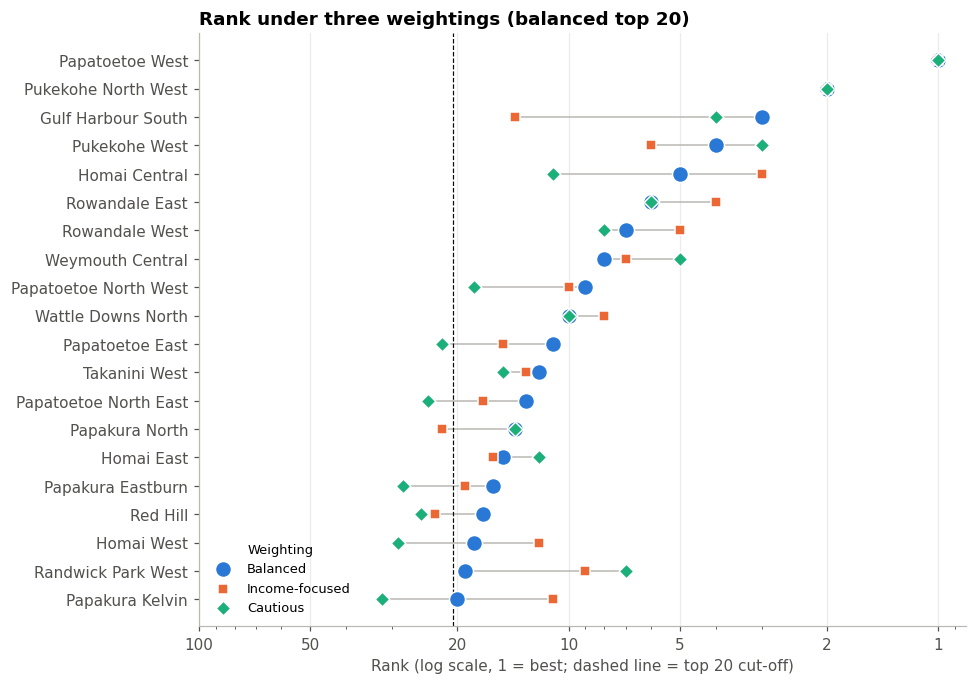

In the top 20 under all three weightings: Papatoetoe West, Pukekohe North West, Gulf Harbour South, Pukekohe West, Homai Central, Rowandale East, Rowandale West, Weymouth Central, Papatoetoe North West, Wattle Downs North, Takanini West, Homai East, Randwick Park West


In [9]:
# STEP 7: SENSITIVITY. Same data, three weightings. A robust shortlist survives all three.
names = list(PROFILES)
top_sets = {n: set(u.nsmallest(20, f'rank_{n}').sa2_code) for n in names}
robust = set.intersection(*top_sets.values())
print(f'Top-20 overlap: Balanced & Income-focused {len(top_sets["Balanced"] & top_sets["Income-focused"])}, '
      f'Balanced & Cautious {len(top_sets["Balanced"] & top_sets["Cautious"])}, in all three: {len(robust)}')
print('Rank correlation between weightings (Spearman):')
print(u[[f'score_{n}' for n in names]].corr(method='spearman').round(2).to_string())

d = u.sort_values('rank_Balanced').head(20).iloc[::-1]
colours = dict(zip(names, [BLUE, ORANGE, '#1baf7a']))   # palette slots 1-3 in fixed order
markers = dict(zip(names, ['o', 's', 'D']))              # shape as a second cue, so colour isn't the only one
fig, ax = plt.subplots(figsize=(9, 7))
ypos = np.arange(len(d)); rk = d[[f'rank_{n}' for n in names]]
ax.hlines(ypos, rk.min(axis=1), rk.max(axis=1), color=GREY, lw=1)
for n, size in zip(names, [110, 46, 46]):   # Balanced drawn larger underneath, so it shows when ranks tie
    ax.scatter(d[f'rank_{n}'], ypos, s=size, color=colours[n], marker=markers[n], edgecolor='white', linewidth=1, label=n, zorder=3)
ax.set_yticks(ypos, d.sa2_name); ax.set_xscale('log'); ax.invert_xaxis()
ax.set_xticks([1, 2, 5, 10, 20, 50, 100]); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f}'))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.axvline(20.5, color=INK, lw=0.8, ls='--')
ax.grid(axis='y', visible=False)
ax.legend(frameon=False, loc='lower left', title='Weighting', title_fontsize=8.5, fontsize=8.5)
ax.set(title='Rank under three weightings (balanced top 20)', xlabel='Rank (log scale, 1 = best; dashed line = top 20 cut-off)')
fig.savefig(VIZ / '04_weight_sensitivity.png'); plt.show()
print('In the top 20 under all three weightings:', ', '.join(u[u.sa2_code.isin(robust)].sort_values('rank_Balanced').sa2_name))

In [10]:
# STEP 7b: MISSING-DATA RULE. The previous version scored all screened SA2s and averaged only the measures each one had.
# Recompute that way and compare with the complete-input ranking on the SAME SA2s (the ones with all seven inputs).
prev = group_scores(percentile_scores(all_screened[~all_screened.is_new_development].copy()))
same = u[['sa2_code', 'sa2_name', 'rank_Balanced', 'score_Balanced']].merge(
    prev[['sa2_code', 'rank_Balanced', 'score_Balanced']], on='sa2_code', suffixes=('', '_prev'))
rho_rule = same.score_Balanced.corr(same.score_Balanced_prev, method='spearman')
top_new, top_prev = set(u.nsmallest(20, 'rank_Balanced').sa2_code), set(prev.nsmallest(20, 'rank_Balanced').sa2_code)
pv = prev.set_index('sa2_code')
print(f'Top-20 overlap, complete-input rule vs previous skip-missing rule: {len(top_new & top_prev)} of 20')
print('Left the top 20:', ', '.join(f'{pv.sa2_name[c]} (missing: {pv.missing_inputs[c] or "nothing"})' for c in top_prev - top_new) or 'none')
print('Entered the top 20:', ', '.join(pv.sa2_name[c] for c in top_new - top_prev) or 'none')
# re-rank the previous scores within the same SA2s, so positions compare like for like
same['rank_prev_same'] = same.score_Balanced_prev.rank(ascending=False, method='min')
shift = (same.rank_Balanced - same.rank_prev_same).abs()
print(f'Rank agreement over the same {len(same)} SA2s (Spearman, balanced score): {rho_rule:.4f}')
print(f'Rank change within those SA2s: median {shift.median():.0f}, 90th percentile {shift.quantile(.9):.0f}, max {shift.max():.0f} places')

Top-20 overlap, complete-input rule vs previous skip-missing rule: 18 of 20
Left the top 20: Warkworth East (missing: nothing), Wellsford (missing: nothing)
Entered the top 20: Randwick Park West, Papakura Kelvin
Rank agreement over the same 481 SA2s (Spearman, balanced score): 0.9998
Rank change within those SA2s: median 1, 90th percentile 4, max 11 places


In [11]:
# STEP 7c: TWO MORE CHOICES, each compared with the ranking above (complete inputs, new developments listed, bonds split by
# rented households): (1) ranking new developments too; (2) the previous even split of shared bonds.
def rerank(d):
    return group_scores(percentile_scores(d.copy()))
cur = set(u.nsmallest(20, 'rank_Balanced').sa2_code)
nm = all_screened.set_index('sa2_code').sa2_name
for label, d in [('New developments ranked too', all_screened[all_screened.missing_inputs == '']),
                 ('Shared bonds split evenly', u.assign(bonds_per_sa2=u.bonds_per_sa2_even))]:
    r = rerank(d); alt = set(r.nsmallest(20, 'rank_Balanced').sa2_code)
    j = u[['sa2_code', 'score_Balanced']].merge(r[['sa2_code', 'score_Balanced']], on='sa2_code')
    print(f'{label}: top-20 overlap {len(cur & alt)} of 20 | Spearman over the {len(j)} ranked SA2s '
          f'{j.score_Balanced_x.corr(j.score_Balanced_y, method="spearman"):.3f}')
    print('   in that version, not this one:', ', '.join(nm[c] for c in alt - cur) or 'none',
          '| in this one, not that:', ', '.join(nm[c] for c in cur - alt) or 'none')
ratio = (u.bonds_per_sa2 / u.bonds_per_sa2_even)[u.flag_borrowed_rent]
print(f'Shared-rent SA2s: rented-household split / even split, 5th-95th percentile {ratio.quantile(.05):.2f}-{ratio.quantile(.95):.2f}')

New developments ranked too: top-20 overlap 17 of 20 | Spearman over the 481 ranked SA2s 1.000
   in that version, not this one: Takanini South East, Takanini McLennan, Pukekohe South West | in this one, not that: Homai West, Papakura Kelvin, Homai East
Shared bonds split evenly: top-20 overlap 19 of 20 | Spearman over the 481 ranked SA2s 0.999
   in that version, not this one: Wellsford | in this one, not that: Papakura Eastburn
Shared-rent SA2s: rented-household split / even split, 5th-95th percentile 0.61-1.54


**Reading this (Step 7c):**
- **New developments.** Ranking the 15 too would put Pukekohe South West (#1 before), Takanini South East and Takanini
  McLennan in the top 20. Their population growth (+116% to +808%) is real, but their 10-year rent growth and volatility come
  from the older housing of the 2018 area they share rent with. Capping population growth would not fix this: scores are
  percentile ranks, so +808% and +31% already score about the same.
- **Bond split.** Splitting a shared source SA2's bonds by rented households instead of evenly moves 1 of the top 20
  (Papakura Eastburn in, Wellsford out; Spearman 0.999). For shared-rent SA2s the new figure is 0.6–1.5 times the old one.

**Reading this (missing-data rule):** the previous version averaged only the measures each SA2 had, so an SA2 with no
rent volatility was scored on its other three risk measures, which gave them more weight. With new developments set aside in
both versions, ranking only complete SA2s changes **2 of the top 20** (Warkworth East and Wellsford leave; Randwick Park West
and Papakura Kelvin enter). They leave because the 34 incomplete SA2s no longer shift everyone's percentiles, not because
they lack an input. Over the same 480 SA2s the two rules agree almost perfectly (Spearman 0.9998; median shift 1 place,
largest 11).

**Reading this:** the ranking is fairly robust. All three weightings agree closely overall (rank correlation 0.92–0.97),
13 SA2s are in the top 20 under all three, and the biggest swings come from SA2s that are strong on one group and weak on
another (Gulf Harbour South falls from 3 to 14 when income is weighted more; Papakura Kelvin falls from 20 to 32 and Homai
Central from 5 to 11 when risk is weighted more; Randwick Park West rises from 19 to 7). On the dashboard, let the user move the weights and
show this rank-range view, rather than presenting one "best" list.

### Step 8: Map of the balanced score

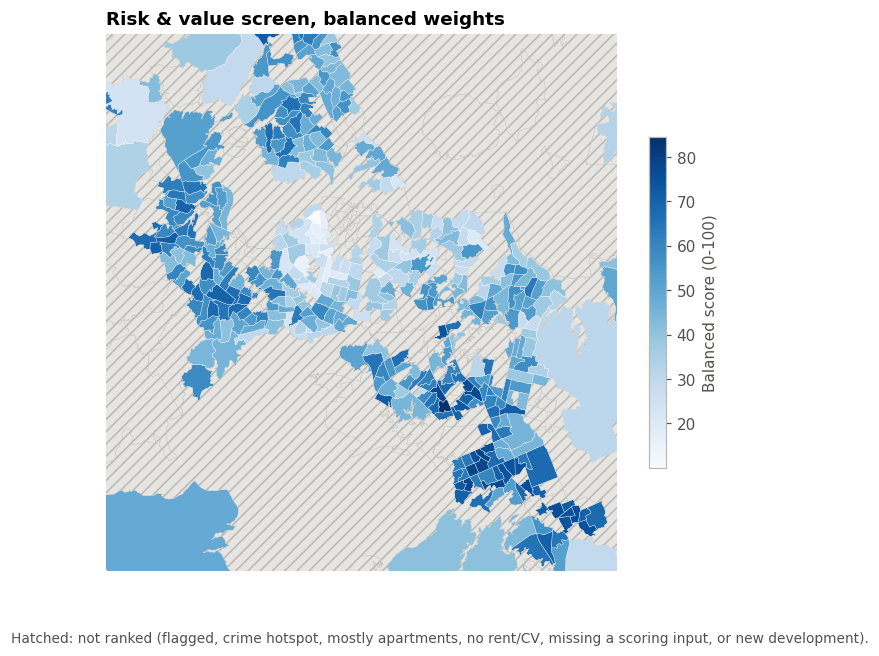

Median balanced score by area type:


,median,size
area_type,,
Crowded family suburbs,63.8,97
Middle suburbs,54.5,156
Older & coastal,52.1,41
Outer suburbs & lifestyle blocks,45.5,93
Affluent established suburbs,34.6,94


In [12]:
# STEP 8: MAP
gm = geo[['sa2_code', 'geometry']].merge(u[['sa2_code', 'score_Balanced']], on='sa2_code', how='left')
ok, out_ = gm[gm.score_Balanced.notna()], gm[gm.score_Balanced.isna()]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ok.plot(column='score_Balanced', cmap=SEQ, ax=ax, edgecolor='white', linewidth=0.2,
        legend=True, legend_kwds={'label': 'Balanced score (0-100)', 'shrink': 0.6})
out_.plot(ax=ax, color='#e6e5e1', hatch='///', edgecolor=GREY, linewidth=0.2)
ax.set_title('Risk & value screen, balanced weights'); ax.set_axis_off(); ax.set_xlim(174.55, 175.0); ax.set_ylim(-37.1, -36.72)
fig.text(0.01, 0.02, 'Hatched: not ranked (flagged, crime hotspot, mostly apartments, no rent/CV, missing a scoring input, or new development).', color=MUTED, fontsize=9)
fig.savefig(VIZ / '04_score_map.png'); plt.show()
print('Median balanced score by area type:')
u.groupby('area_type').score_Balanced.agg(['median', 'size']).sort_values('median', ascending=False).round(1)

### Step 9: Save outputs

In [13]:
# STEP 9: SAVE
keep = ['sa2_code', 'sa2_name', 'area_type', 'median_cv_2024', 'median_rent_weekly', 'rent_3bed_house', 'lodged_3bed_house_4q',
        'flag_verify_3bed_house', 'gross_yield_pct',
        'rent_cagr_10y_pct', 'pop_change_2018_2023_pct', 'crime_per_1000_residents', 'rent_volatility', 'cv_change_2021_2024_pct',
        'active_bonds', 'bond_share', 'bonds_per_sa2', 'rent_change_2y_pa', *[f's_{c}' for c in measures.col], 'value_score',
        'growth_score', 'risk_score', 'risk_tier', *[f'score_{n}' for n in PROFILES], *[f'rank_{n}' for n in PROFILES],
        'rent_source_sa2', 'flag_borrowed_rent', 'is_new_development', 'flag_rapid_growth', 'ranked', 'missing_inputs',
        'not_ranked_reason']
out = CLEAN / 'risk_value_screen.csv'
# ranked SA2s first (by rank), then the unranked ones (missing an input, or new development) with the reason and no scores
res = pd.concat([u, incomplete, newdev]).assign(ranked=lambda d: d.sa2_code.isin(u.sa2_code))
res['not_ranked_reason'] = np.select([res.ranked, res.missing_inputs != ''],
                                     ['', 'missing: ' + res.missing_inputs],
                                     "new development: rent history is the shared 2018 source area's older housing")
res.reindex(columns=keep).round(2).sort_values(['ranked', 'rank_Balanced'], ascending=[False, True]).to_csv(out, index=False)
check = pd.read_csv(out)
assert len(check) == len(all_screened) and check.sa2_code.is_unique and check.ranked.sum() == len(u)
assert check.score_Balanced.dropna().between(0, 100).all() and check.loc[~check.ranked, 'score_Balanced'].isna().all()
print(f'Saved {out} ({check.shape[0]} rows, {check.shape[1]} columns)')
print('Charts:', ', '.join(sorted(p.name for p in VIZ.glob('04_*.png'))))

Saved data\clean\risk_value_screen.csv (530 rows, 42 columns)
Charts: 04_score_map.png, 04_top20_scores.png, 04_weight_sensitivity.png, 04_yield_vs_growth.png


# File 4: Risk & Value Screen - Summary

## What we did
Screened 530 house-dominated, analysis-ready SA2s (1.50 million residents) and ranked 481: those with all seven inputs,
leaving out 15 new developments whose rent is borrowed from a shared 2018 source area's older housing. Three groups:
value (gross yield, a 2024 council-CV proxy), growth (10-year rent growth, population growth 2018–23) and risk (recorded
victimisations per 1,000 residents, rent volatility, CV fall 2021–24, rental market depth). The 34 SA2s missing an input are
listed with what is missing (29 lack only rent volatility, 1 also lacks 10-year rent growth, 3 lack only 10-year rent growth,
1 lacks population change). Each measure is a percentile rank; groups are averaged and combined under three
weightings. Output: `data/clean/risk_value_screen.csv` (unranked SA2s carry `not_ranked_reason`).

## Decisions to review
| Decision | Why | Alternative |
|---|---|---|
| Only SA2s with 50%+ separate houses | Yield is only like-for-like where rent and CV both mostly describe houses | Score apartments separately |
| Crime hotspots excluded | Per-resident rate not comparable (File 1) | Use crime counts per km² |
| Demographics not used as risk | They describe people, not investment outcomes | — |
| Bonds of a shared MBIE source SA2 split by rented households | A large SA2 shouldn't get the same rental market as a small one | Even split (previous rule): top 20 differs by 1 SA2 |
| Rank only SA2s with all 7 inputs; list the other 34 | Skipping a missing input re-weights that SA2's other measures | Skip-missing average (previous rule): top 20 differs by 2 SA2s |
| New developments (population more than doubled 2018–23 and rent borrowed from a shared 2018 source SA2) listed, not ranked | Their rent history is the source area's older housing | Rank them: Pukekohe South West, Takanini South East and Takanini McLennan enter the top 20 |
| Fast growth with its own rent series stays ranked (`flag_rapid_growth`: Long Bay) | Its rent history is its own area's | — |
| Two-year rent change shown, not scored | Noisy; any weight would be a guess | Blend into growth (0.5/0.3/0.2 keeps 16 of the top 20) |
| Percentile ranks, equal weights within a group | Simple, explainable, immune to outliers | z-scores; expert weights |

## Key findings
1. **The screen points to South Auckland.** The top 20 are mostly Papatoetoe, Takanini, Pukekohe, Papakura and Manurewa,
   with CVs of \$690k–980k, yields of 3.8–4.8% and 10-year rent growth of 3.2–4.6% a year. Affluent established suburbs rank lowest (median score 35).
2. **The ranking is robust to weights.** Rank correlation 0.92–0.97 between weightings; 13 SA2s are in the top 20 under all three.
3. **The ranking is robust to the method choices.** Against the previous rules: missing-data rule 18 of 20 shared, bond split
   19 of 20. Ranking the 15 new developments too would bring in Pukekohe South West, Takanini South East and Takanini McLennan.
4. **The top is thinner than it looks.** 11 of the top 20 share their rent figure with another SA2: 16 distinct rental markets.
   6 of the top 20 have a 3-bed house rent marked `verify` (21–27 new lodgements a year).
5. **Past growth, recent cooling.** The score rewards 10-year rent growth, but 15 of the top 20 saw rent fall over the last two
   years (median −1.4% a year, against −0.7% for the rest). Read the score as past performance next to `rent_change_2y_pa`.
6. **Crime is the trade-off at the top.** 16 of the top 20 have above-median recorded victimisations per resident for the screened areas; strong yield and growth
   outweigh it in the average. The heatmap shows this rather than hiding it, and the Cautious weighting is the one to use if crime matters.
7. **Value, growth and risk are nearly independent** (correlations 0.11–0.28), so no single measure stands in for the others.

## What this means for the dashboard
- A screen page with weight sliders, the measure heatmap, and the rank-range chart, not a fixed "top 10".
- Always show the shared-rent label and the 3-bed house rent next to the score; label yield as a 2024 CV proxy and crime
  as recorded victimisations per resident, with the visitor and Police coverage caveats.
- List unranked SA2s with `not_ranked_reason` instead of hiding them. Badge new developments: "New development zone –
  historical rent metrics reflect the 2018 parent area"; badge `flag_rapid_growth` SA2s "Rapid growth".
- Show `lodged_3bed_house_4q` and the `verify` mark next to the 3-bed house rent.
- Show `rent_change_2y_pa` next to the 10-year rent growth.
- Carry the "research screen, not advice" note and the missing-risk list below.

## Missing risks (not in the data)
- Insurance cost, body-corporate fees, rates, maintenance, vacancy and tenant turnover.
- Zoning and future supply (new subdivisions can hold rents down nearby).
- CVs are council valuations from 2024, not sale prices.

## Next
- Start the Streamlit dashboard.